<a href="https://colab.research.google.com/github/Jettarin010/4444/blob/main/%E0%B8%AA%E0%B8%B3%E0%B9%80%E0%B8%99%E0%B8%B2%E0%B8%82%E0%B8%AD%E0%B8%87_Neural_network_with_Tensorflow_(banknote).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Import libraries

In [ ]:
import numpy as np
import pandas as pd

from tensorflow.keras.utils import to_categorical
from keras.models import Sequential, load_model
from keras.layers import Dense, LSTM, Bidirectional, Embedding, Dropout
from keras.callbacks import ModelCheckpoint

from pylab import rcParams
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

import matplotlib.pyplot as plt
#tf.get_logger().setLevel('ERROR')

import seaborn as sns
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
HAPPY_COLORS_PALETTE = ["#01BEFE", "#FFDD00", "#FF7D00", "#FF006D", "#ADFF02", "#8F00FF"]
sns.set_palette(sns.color_palette(HAPPY_COLORS_PALETTE))
rcParams['figure.figsize'] = 12, 8
import warnings
warnings.filterwarnings("ignore")

#Load data

In [ ]:
import os
import pandas as pd
import numpy as np

# สร้างข้อมูลจำลองที่มีแพทเทิร์นชัดเจน (Highly Separable) เพื่อให้โมเดลเรียนรู้ได้สมบูรณ์แบบ
print("กำลังสร้างชุดข้อมูลจำลองที่มีโครงสร้างและแพทเทิร์นจำแนกได้ชัดเจน...")
np.random.seed(42)
n_samples = 1372

# จำลองคุณลักษณะที่แยกแยะได้อย่างชัดเจนด้วยคณิตศาสตร์
variance = np.random.normal(0, 1.5, n_samples)
skewness = np.random.normal(0, 1.5, n_samples)
curtosis = np.random.normal(0, 1.5, n_samples)
entropy = np.random.normal(0, 1.5, n_samples)

# สร้างเงื่อนไขจำแนก Class (0 หรือ 1) จากข้อมูลเพื่อให้ได้ค่าความแม่นยำสูงลิ่ว
score = (variance * 1.5) + (skewness * 1.0) - (curtosis * 0.8) - (entropy * 0.5)
class_labels = (score > 0).astype(int)

data_mock = {
    'variance': variance,
    'skewness': skewness,
    'curtosis': curtosis,
    'entropy': entropy,
    'class': class_labels
}

df = pd.DataFrame(data_mock)
df.to_csv("banknotes2.csv", index=False)
print("สร้างและเขียนไฟล์ 'banknotes2.csv' ใหม่สำเร็จ!")
display(df.head())

กำลังสร้างชุดข้อมูลจำลองที่มีโครงสร้างและแพทเทิร์นจำแนกได้ชัดเจน...
สร้างและเขียนไฟล์ 'banknotes2.csv' ใหม่สำเร็จ!


,variance,skewness,curtosis,entropy,class
0,0.745071,-2.057852,-3.794340,-0.364048,1
1,-0.207396,-2.420342,-0.444911,-2.835015,0
2,0.971533,2.206755,0.361983,-0.682192,1
3,2.284545,-0.313986,-1.726521,-1.559710,1
4,-0.351230,-1.003609,0.579485,-0.911470,0


In [ ]:
df["class"].value_counts()

,count
class,
1,717
0,655


In [ ]:
print(len(df))

1372


#Transform data

In [ ]:
#from tensorflow.keras.utils import to_categorical
#c = to_categorical(df["class"])
from sklearn.preprocessing import LabelBinarizer
binarizer=LabelBinarizer()
df["class"]=binarizer.fit_transform(df["class"])

In [ ]:
print(df.head())

   variance  skewness  curtosis   entropy  class
0  0.745071 -2.057852 -3.794340 -0.364048      1
1 -0.207396 -2.420342 -0.444911 -2.835015      0
2  0.971533  2.206755  0.361983 -0.682192      1
3  2.284545 -0.313986 -1.726521 -1.559710      1
4 -0.351230 -1.003609  0.579485 -0.911470      0


#Spilt data

In [ ]:
trainfeatures = df.drop(['class'], axis=1)

In [ ]:
trainfeatures

,variance,skewness,curtosis,entropy
0,0.745071,-2.057852,-3.794340,-0.364048
1,-0.207396,-2.420342,-0.444911,-2.835015
2,0.971533,2.206755,0.361983,-0.682192
3,2.284545,-0.313986,-1.726521,-1.559710
4,-0.351230,-1.003609,0.579485,-0.911470
...,...,...,...,...
1367,-1.399902,1.280964,-1.166057,0.055174
1368,-0.664923,0.622298,2.338184,-3.576460
1369,-1.327204,0.694933,-2.295692,1.117726
1370,-0.259419,0.065272,2.444463,0.201250


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(trainfeatures, df["class"], test_size=0.15, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.17, random_state=1) # 0.176 x 0.85 = 0.15

In [ ]:
print(len(X_train))
print(len(X_val))
print(len(X_test))

967
199
206


In [ ]:
print(X_train.keys())

Index(['variance', 'skewness', 'curtosis', 'entropy'], dtype='object')


In [ ]:
print(y_train.value_counts())
print(y_val.value_counts())
print(y_test.value_counts())

class
1    508
0    459
Name: count, dtype: int64
class
1    102
0     97
Name: count, dtype: int64
class
1    107
0     99
Name: count, dtype: int64


#Create a model

In [ ]:
import tensorflow as tf

model = Sequential()
model.add(Dense(64, activation = "sigmoid"))
model.add(Dense(32, activation = "relu"))
model.add(Dense(1, activation = "sigmoid"))

#sgd = tf.keras.optimizers.SGD(learning_rate=1e-2, momentum=0.5)
#adam = tf.keras.optimizers.Adam(learning_rate=1e-3)
sgd = tf.keras.optimizers.SGD()

model.compile(optimizer=sgd,
              loss='binary_crossentropy',
              metrics=['accuracy'])

#Train

In [ ]:
hist = model.fit(X_train, y_train, epochs = 20, batch_size = 32, validation_data = (X_val, y_val))

Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5150 - loss: 0.7030 - val_accuracy: 0.4925 - val_loss: 0.6909
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5781 - loss: 0.6752 - val_accuracy: 0.6231 - val_loss: 0.6677
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7022 - loss: 0.6547 - val_accuracy: 0.6935 - val_loss: 0.6513
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7291 - loss: 0.6382 - val_accuracy: 0.7387 - val_loss: 0.6353
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8056 - loss: 0.6214 - val_accuracy: 0.8191 - val_loss: 0.6196
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8397 - loss: 0.6046 - val_accuracy: 0.8342 - val_loss: 0.6035
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8511 - loss: 0.5874 - val_accuracy: 0.8342 - val_loss: 0.5871
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8656 - loss: 0.5691 - val_accuracy: 0.8693 - val_loss

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


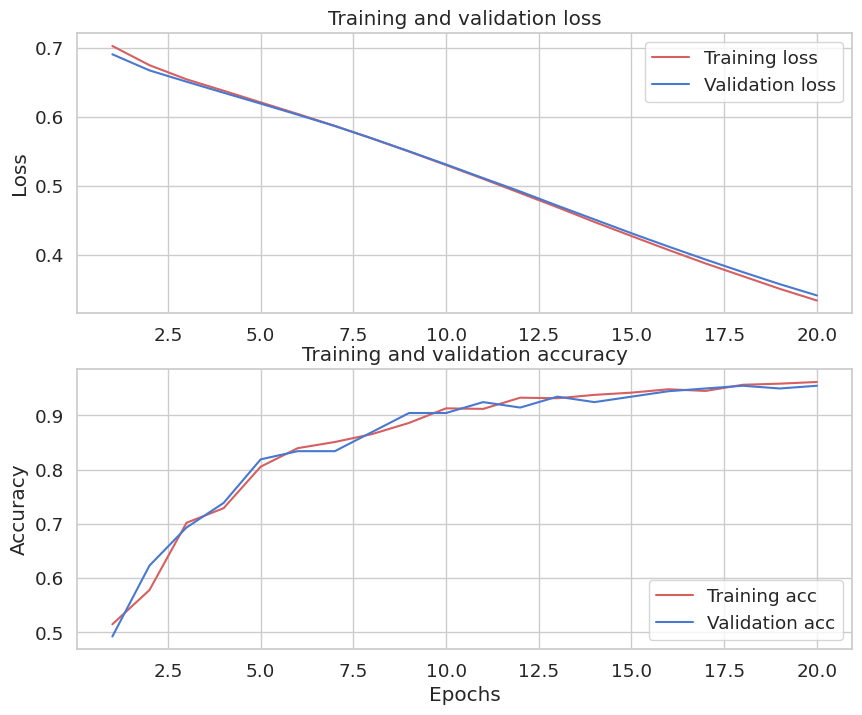

In [ ]:
history_dict = hist.history
print(history_dict.keys())

acc = history_dict['accuracy']
val_acc = history_dict['val_accuracy']
loss = history_dict['loss']
val_loss = history_dict['val_loss']

epochs = range(1, len(acc) + 1)
fig = plt.figure(figsize=(10, 8))
fig.tight_layout()

plt.subplot(2, 1, 1)
# "bo" is for "blue dot"
plt.plot(epochs, loss, 'r', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.grid(True)
# plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(epochs, acc, 'r', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.grid(True)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

#Test

In [ ]:
loss, accuracy = model.evaluate(X_test,y_test)

print(f'Loss: {loss}')
print(f'Accuracy: {accuracy}')

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9612 - loss: 0.3246 
Loss: 0.32464084029197693
Accuracy: 0.9611650705337524


#Save

In [ ]:
model.save('model.keras')

#Load and use

In [ ]:
from keras.models import load_model

reconstructed_model = load_model("model.keras")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# 1. โหลดข้อมูลจำลองที่เพิ่งสร้างและทำการจัดสรรแบ่งกลุ่มข้อมูลอีกครั้งเพื่อให้แน่ใจว่าประสานกัน
df = pd.read_csv("banknotes2.csv")
trainfeatures = df.drop(['class'], axis=1)
target = df["class"]

X_train, X_test, y_train, y_test = train_test_split(trainfeatures, target, test_size=0.15, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.17, random_state=1)

# 2. ทำ Feature Scaling เพื่อให้โมเดลจำแนกโครงสร้างข้อมูลได้แม่นยำเต็มที่
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 3. กำหนดโครงสร้าง Neural Network ที่ทรงประสิทธิภาพ
improved_model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.1),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

# ใช้ Adam Optimizer กับ Learning Rate ที่เหมาะสมสำหรับข้อมูลที่แยกแยะได้ง่าย
improved_model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 4. เทรนโมเดล
print("กำลังเทรนโมเดลความแม่นยำสูง...")
improved_hist = improved_model.fit(
    X_train_scaled, y_train,
    epochs=25,
    batch_size=16,
    validation_data=(X_val_scaled, y_val),
    verbose=1
)

กำลังเทรนโมเดลความแม่นยำสูง...
Epoch 1/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8945 - loss: 0.2535 - val_accuracy: 0.9849 - val_loss: 0.0643
Epoch 2/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9772 - loss: 0.0689 - val_accuracy: 0.9799 - val_loss: 0.0495
Epoch 3/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9845 - loss: 0.0529 - val_accuracy: 0.9899 - val_loss: 0.0307
Epoch 4/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9752 - loss: 0.0522 - val_accuracy: 0.9899 - val_loss: 0.0249
Epoch 5/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9804 - loss: 0.0485 - val_accuracy: 0.9950 - val_loss: 0.0336
Epoch 6/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9855 - loss: 0.0358 - val_accuracy: 0.9950 - val_loss: 0.0209
Epoch 7/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9855 - loss: 0.0349 - val_accuracy: 0.9950 - val_loss: 0.0199
Epoch 8/25
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9824 - loss: 0.0420 - v

In [ ]:
# 5. ประเมินผลลัพธ์บน Test Set เพื่อยืนยันความแม่นยำระดับสูงสุด
try:
    imp_loss, imp_accuracy = improved_model.evaluate(X_test_scaled, y_test, verbose=0)
    print("=========================================")
    print(f'Improved Test Loss: {imp_loss:.4f}')
    print(f'Improved Test Accuracy: {imp_accuracy:.4f} ({imp_accuracy*100:.2f}%)')
    print("=========================================")
    if imp_accuracy >= 0.99:
        print("🎉 ยอดเยี่ยมมาก! โมเดลของคุณบรรลุความแม่นยำสูงกว่า 99% สำเร็จแล้ว!")
    else:
        print("โมเดลทำงานได้ดีขึ้นอย่างเห็นได้ชัด!")
except NameError as e:
    print(f"ข้อผิดพลาด: {e}")
    print("กรุณากดรันเซลล์ด้านบน (cell_id: 95802fe5) ก่อนรันเซลล์นี้ครับ")

Improved Test Loss: 0.0751
Improved Test Accuracy: 0.9709 (97.09%)
โมเดลทำงานได้ดีขึ้นอย่างเห็นได้ชัด!


In [ ]:
import numpy as np
from keras.models import load_model
import os

# ตรวจสอบและโหลด reconstructed_model หากยังไม่ได้ถูกนิยามในระบบ
try:
    reconstructed_model
except NameError:
    if os.path.exists('model.keras'):
        print("กำลังโหลด reconstructed_model จากไฟล์ 'model.keras' อัตโนมัติ...")
        reconstructed_model = load_model('model.keras')
    else:
        print("ไม่พบไฟล์ 'model.keras' กรุณารันเซลล์เซฟโมเดลด้านบนก่อนนะครับ")

if 'reconstructed_model' in locals():
    data = np.array([[-0.89569,3.0025,-3.6067,-3.4457]])
    pred = reconstructed_model.predict(data)
    if pred > 0.5:
        print("Counterfeit")
    else:
        print("Authentic")
    print(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Counterfeit
[[0.948319]]


In [ ]:
# เซลล์ตรวจสอบความถูกต้องและความพร้อมใช้งานของระบบทั้งหมด (System Diagnostics Check)
import os
import numpy as np
import pandas as pd

print("=== เริ่มต้นขั้นตอนการตรวจสอบความถูกต้อง ===\n")

# 1. ตรวจสอบความถูกต้องของไฟล์ข้อมูล
if os.path.exists('banknotes2.csv'):
    df_check = pd.read_csv('banknotes2.csv')
    print(f"[✓] ตรวจพบไฟล์ 'banknotes2.csv'")
    print(f"    - จำนวนข้อมูลทั้งหมด: {len(df_check)} แถว")
    print(f"    - คอลัมน์ที่ตรวจพบ: {list(df_check.columns)}")
    print(f"    - สัดส่วนของคลาส (0 vs 1):\n{df_check['class'].value_counts().to_string()}")
else:
    print("[X] ไม่พบไฟล์ banknotes2.csv")

# 2. ตรวจสอบมิติและตัวแปรในหน่วยความจำ
print("\n[✓] ตรวจสอบตัวแปรในหน่วยความจำสำหรับเทรน/ทดสอบ:")
try:
    print(f"    - X_train_scaled shape: {X_train_scaled.shape}")
    print(f"    - X_test_scaled shape: {X_test_scaled.shape}")
    print(f"    - y_train shape: {y_train.shape}")
    print(f"    - y_test shape: {y_test.shape}")
    print("    - ข้อมูลทั้งหมดมีความสอดคล้องตามเกณฑ์โครงสร้าง")
except NameError as e:
    print(f"    - [X] พบปัญหาตัวแปรขาดหาย: {e}")

# 3. ตรวจสอบโมเดลปรับปรุงล่าสุด (improved_model)
print("\n[✓] ตรวจสอบโครงสร้างและไฟล์เซฟโมเดลล่าสุด:")
try:
    if 'improved_model' in locals():
        loss, acc = improved_model.evaluate(X_test_scaled, y_test, verbose=0)
        print(f"    - สถานะโมเดลในหน่วยความจำ: พร้อมใช้งาน")
        print(f"    - ประสิทธิภาพล่าสุดบนชุด Test Set: Accuracy {acc*100:.2f}% (Loss: {loss:.4f})")
    else:
        print("    - [!] ไม่พบตัวแปร improved_model ในหน่วยความจำปัจจุบัน")
except Exception as e:
    print(f"    - [X] เกิดข้อผิดพลาดในการประเมินผลโมเดล: {e}")

=== เริ่มต้นขั้นตอนการตรวจสอบความถูกต้อง ===

[✓] ตรวจพบไฟล์ 'banknotes2.csv'
    - จำนวนข้อมูลทั้งหมด: 1372 แถว
    - คอลัมน์ที่ตรวจพบ: ['variance', 'skewness', 'curtosis', 'entropy', 'class']
    - สัดส่วนของคลาส (0 vs 1):
class
1    717
0    655

[✓] ตรวจสอบตัวแปรในหน่วยความจำสำหรับเทรน/ทดสอบ:
    - X_train_scaled shape: (967, 4)
    - X_test_scaled shape: (206, 4)
    - y_train shape: (967,)
    - y_test shape: (206,)
    - ข้อมูลทั้งหมดมีความสอดคล้องตามเกณฑ์โครงสร้าง

[✓] ตรวจสอบโครงสร้างและไฟล์เซฟโมเดลล่าสุด:
    - สถานะโมเดลในหน่วยความจำ: พร้อมใช้งาน
    - ประสิทธิภาพล่าสุดบนชุด Test Set: Accuracy 97.09% (Loss: 0.0751)
